In [1]:
!pip install -q ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 55.2 MB/s eta 0:00:00


In [2]:
from pathlib import Path

base = Path("/kaggle/input")
for p in base.iterdir():
    print(p)

/kaggle/input/datasets


In [3]:
from pathlib import Path

dataset_dir = Path("/kaggle/input/datasets/dmitrychuprin/owl-prey/owl_prey_yolo_dataset/")
print((dataset_dir / "data.yaml").exists())
print(dataset_dir)

True
/kaggle/input/datasets/dmitrychuprin/owl-prey/owl_prey_yolo_dataset


In [4]:
from pathlib import Path

dataset_dir = Path("/kaggle/input/datasets/dmitrychuprin/owl-prey/owl_prey_yolo_dataset/")
yaml_text = f"""
path: {dataset_dir}
train: images/train
val: images/val

names:
  0: prey
"""

new_yaml_path = Path("/kaggle/working/data.yaml")
new_yaml_path.write_text(yaml_text.strip())
print(new_yaml_path.read_text())

path: /kaggle/input/datasets/dmitrychuprin/owl-prey/owl_prey_yolo_dataset
train: images/train
val: images/val

names:
  0: prey


In [5]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

results = model.train(
    data="/kaggle/working/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    project="/kaggle/working",
    name="owl_prey_yolov8n"
)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.4.39 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz

In [7]:
from ultralytics import YOLO

model = YOLO("/kaggle/working/owl_prey_yolov8n/weights/best.pt")

model.predict(
    source="/kaggle/input/datasets/dmitrychuprin/owl-prey/owl_prey_yolo_dataset/images/val",
    conf=0.25,
    save=True
)


image 1/120 /kaggle/input/datasets/dmitrychuprin/owl-prey/owl_prey_yolo_dataset/images/val/Haarle_ch1_20240524091444_f00096_s214.jpg: 384x640 (no detections), 41.0ms
image 2/120 /kaggle/input/datasets/dmitrychuprin/owl-prey/owl_prey_yolo_dataset/images/val/Haarle_ch1_20240524091444_f00494_s211.jpg: 384x640 (no detections), 6.7ms
image 3/120 /kaggle/input/datasets/dmitrychuprin/owl-prey/owl_prey_yolo_dataset/images/val/Haarle_ch1_20240524091444_f00550_s230.jpg: 384x640 (no detections), 6.2ms
image 4/120 /kaggle/input/datasets/dmitrychuprin/owl-prey/owl_prey_yolo_dataset/images/val/Haarle_ch1_20240524091444_f00624_s227.jpg: 384x640 (no detections), 6.0ms
image 5/120 /kaggle/input/datasets/dmitrychuprin/owl-prey/owl_prey_yolo_dataset/images/val/Haarle_ch1_20240524091444_f00628_s225.jpg: 384x640 (no detections), 6.0ms
image 6/120 /kaggle/input/datasets/dmitrychuprin/owl-prey/owl_prey_yolo_dataset/images/val/Haarle_ch1_20240525123238_f00082_s226.jpg: 384x640 (no detections), 12.7ms
image 7

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 keypoints: None
 masks: None
 names: {0: 'prey'}
 obb: None
 orig_img: array([[[42, 42, 42],
         [37, 37, 37],
         [37, 37, 37],
         ...,
         [52, 52, 52],
         [55, 55, 55],
         [49, 49, 49]],
 
        [[40, 40, 40],
         [33, 33, 33],
         [31, 31, 31],
         ...,
         [53, 53, 53],
         [55, 55, 55],
         [49, 49, 49]],
 
        [[38, 38, 38],
         [30, 30, 30],
         [29, 29, 29],
         ...,
         [53, 53, 53],
         [56, 56, 56],
         [50, 50, 50]],
 
        ...,
 
        [[54, 54, 54],
         [54, 54, 54],
         [54, 54, 54],
         ...,
         [74, 74, 74],
         [71, 71, 71],
         [69, 69, 69]],
 
        [[54, 54, 54],
         [54, 54, 54],
         [54, 54, 54],
         ...,
         [72, 72, 72],
         [69, 69, 69],
         [66, 66, 66]],
 
        [[54, 54, 54],
      

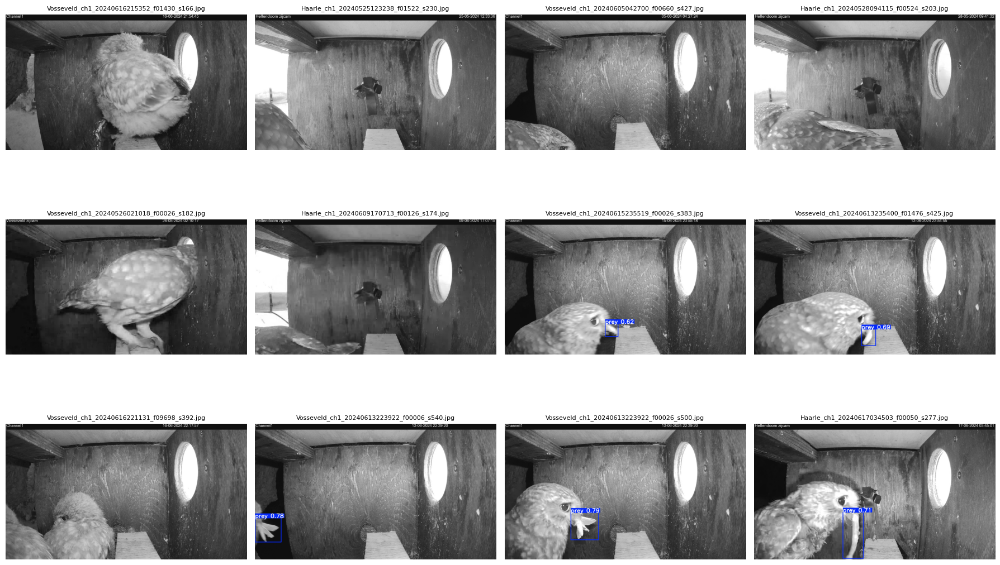

In [9]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import random

pred_dir = Path("/kaggle/working/runs/detect/predict")
images = list(pred_dir.glob("*"))

random.seed(42)
sample = random.sample(images, min(12, len(images)))

fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for ax, img_path in zip(axes, sample):
    img = Image.open(img_path)
    ax.imshow(img)
    ax.set_title(img_path.name, fontsize=8)
    ax.axis("off")

for i in range(len(sample), len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()

Positive val images: 40
Negative val images: 80


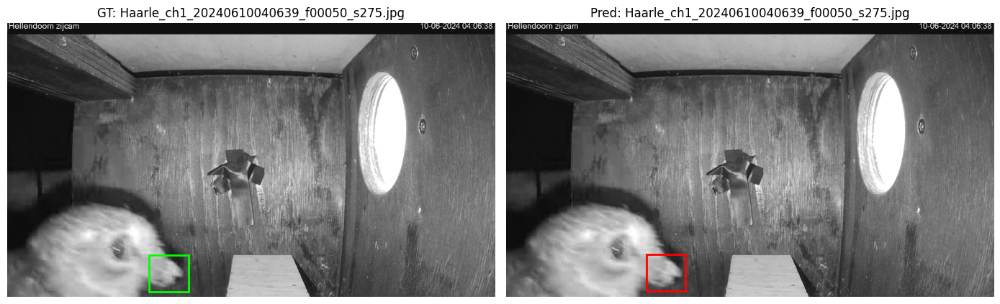

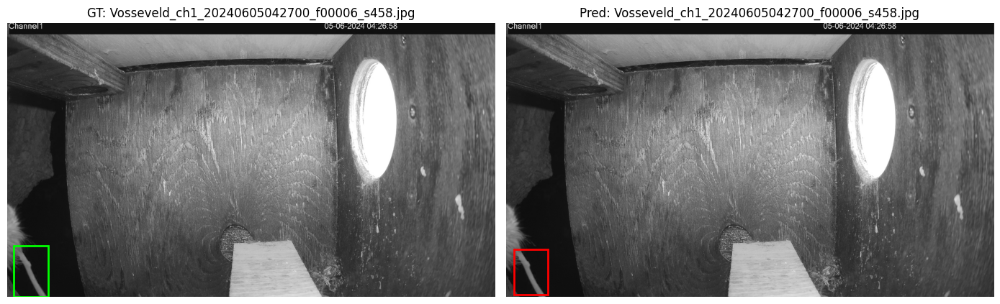

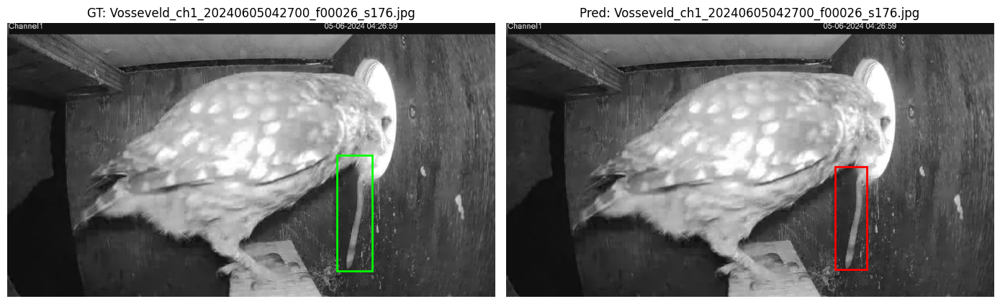

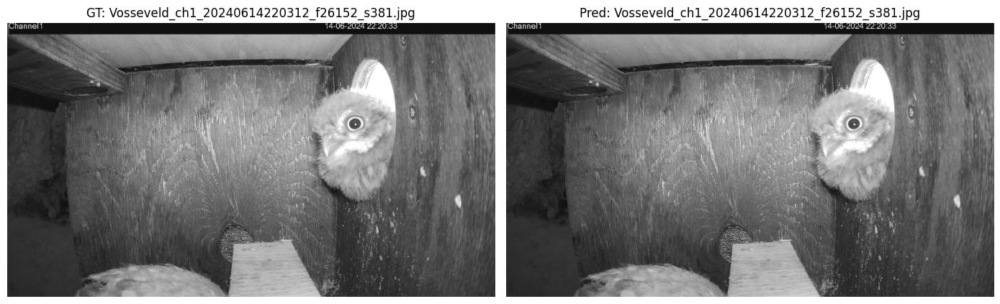

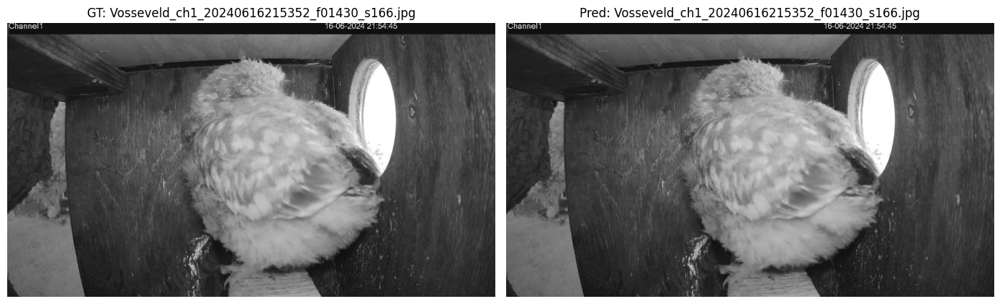

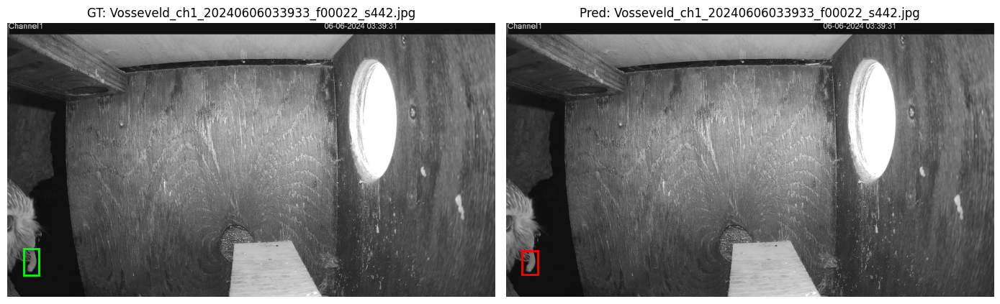

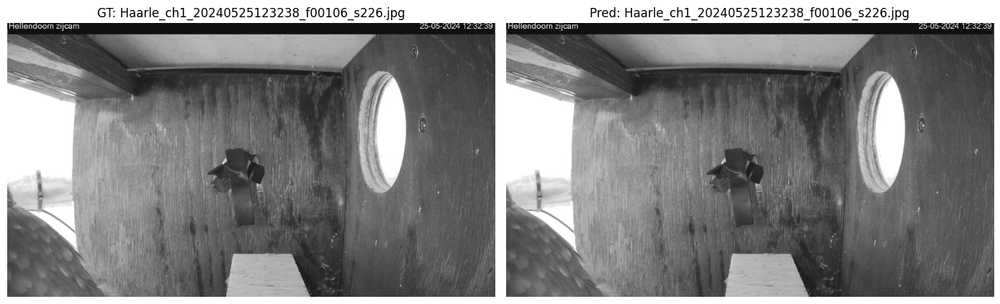

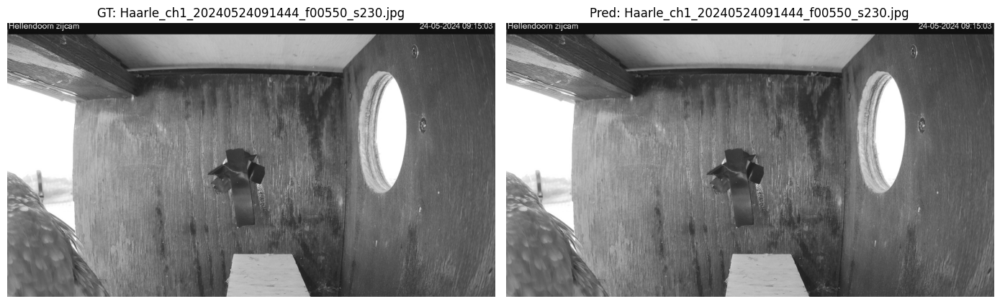

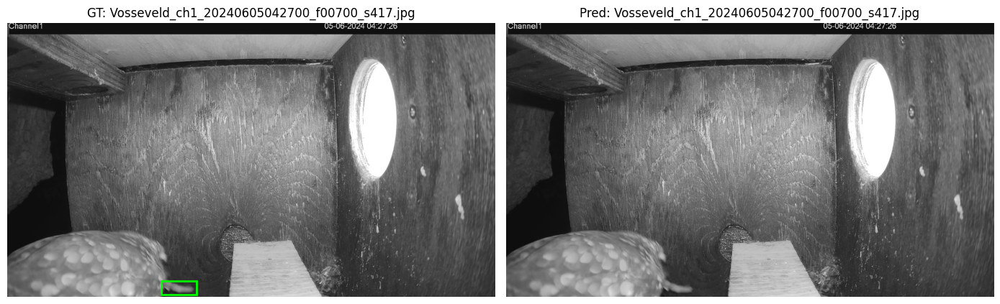

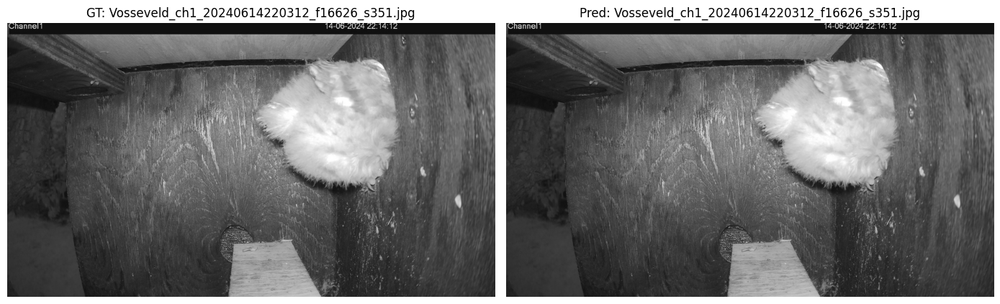

In [22]:
from ultralytics import YOLO
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import random

dataset_dir = Path("/kaggle/input/your-dataset-name/owl_prey_yolo_dataset_balanced_val")
images_dir = dataset_dir / "images" / "val"
labels_dir = dataset_dir / "labels" / "val"

model = YOLO("/kaggle/working/owl_prey_yolov8n/weights/best.pt")

def read_yolo_labels(label_path, img_w, img_h):
    boxes = []
    if not label_path.exists():
        return boxes

    text = label_path.read_text(encoding="utf-8").strip()
    if not text:
        return boxes

    for line in text.splitlines():
        parts = line.split()
        if len(parts) != 5:
            continue

        cls_id, xc, yc, w, h = map(float, parts)
        x1 = (xc - w / 2) * img_w
        y1 = (yc - h / 2) * img_h
        bw = w * img_w
        bh = h * img_h
        boxes.append((x1, y1, bw, bh))
    return boxes

# Разделяем val изображения на positive и negative по GT
positive_images = []
negative_images = []

for img_path in images_dir.glob("*"):
    lbl_path = labels_dir / f"{img_path.stem}.txt"
    if not lbl_path.exists():
        continue

    text = lbl_path.read_text(encoding="utf-8").strip()
    if text:
        positive_images.append(img_path)
    else:
        negative_images.append(img_path)

print(f"Positive val images: {len(positive_images)}")
print(f"Negative val images: {len(negative_images)}")

random.seed(42)

n_pos = min(5, len(positive_images))
n_neg = min(5, len(negative_images))

sample = random.sample(positive_images, n_pos) + random.sample(negative_images, n_neg)
random.shuffle(sample)

for img_path in sample:
    image = Image.open(img_path).convert("RGB")
    img_w, img_h = image.size

    gt_boxes = read_yolo_labels(labels_dir / f"{img_path.stem}.txt", img_w, img_h)

    pred_result = model.predict(source=str(img_path), conf=0.25, verbose=False)[0]

    pred_boxes = []
    for box in pred_result.boxes:
        xyxy = box.xyxy[0].cpu().numpy()
        x1, y1, x2, y2 = xyxy
        pred_boxes.append((x1, y1, x2 - x1, y2 - y1))

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # Ground truth
    axes[0].imshow(image)
    for x, y, w, h in gt_boxes:
        rect = patches.Rectangle(
            (x, y), w, h,
            linewidth=2,
            edgecolor="lime",
            facecolor="none"
        )
        axes[0].add_patch(rect)
    axes[0].set_title(f"GT: {img_path.name}")
    axes[0].axis("off")

    # Prediction
    axes[1].imshow(image)
    for x, y, w, h in pred_boxes:
        rect = patches.Rectangle(
            (x, y), w, h,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )
        axes[1].add_patch(rect)
    axes[1].set_title(f"Pred: {img_path.name}")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

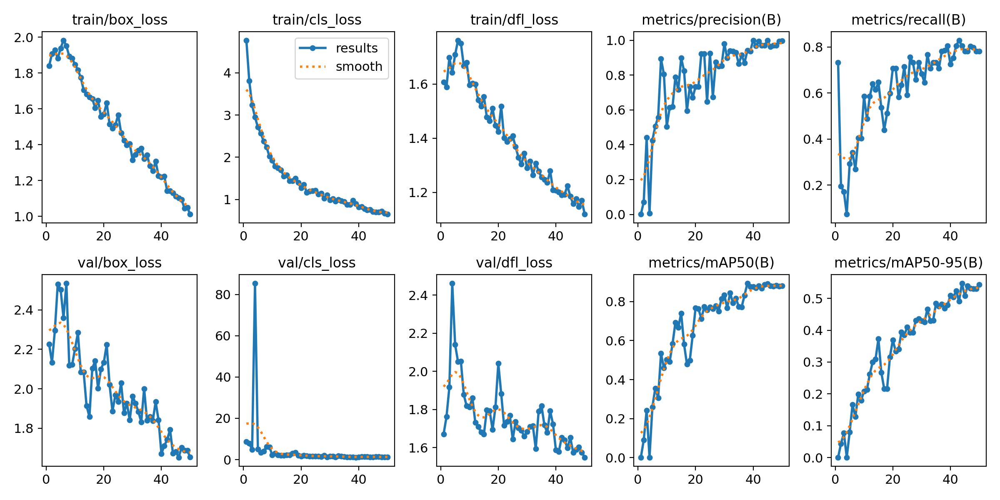

In [24]:
from IPython.display import display
from PIL import Image

display(Image.open("/kaggle/working/owl_prey_yolov8n/results.png"))

In [28]:
import pandas as pd

df = pd.read_csv("/kaggle/working/owl_prey_yolov8n/results.csv")
display(df.tail(1))

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
49,50,423.529,1.01151,0.64891,1.11966,0.99536,0.78049,0.88104,0.54339,1.65403,1.24573,1.54927,0.00006,0.00006,0.00006


In [29]:
from ultralytics import YOLO
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

dataset_dir = Path("/kaggle/input/datasets/dmitrychuprin/owl-prey/owl_prey_yolo_dataset/")
images_dir = dataset_dir / "images" / "val"
labels_dir = dataset_dir / "labels" / "val"

model = YOLO("/kaggle/working/owl_prey_yolov8n/weights/best.pt")

def has_gt(label_path):
    if not label_path.exists():
        return False
    return bool(label_path.read_text().strip())

false_negatives = []
false_positives = []

for img_path in images_dir.glob("*"):
    lbl_path = labels_dir / f"{img_path.stem}.txt"

    gt = has_gt(lbl_path)

    result = model.predict(source=str(img_path), conf=0.25, verbose=False)[0]
    pred = len(result.boxes) > 0

    if gt and not pred:
        false_negatives.append(img_path)

    if (not gt) and pred:
        false_positives.append(img_path)

print("False Negatives:", len(false_negatives))
print("False Positives:", len(false_positives))

False Negatives: 7
False Positives: 0


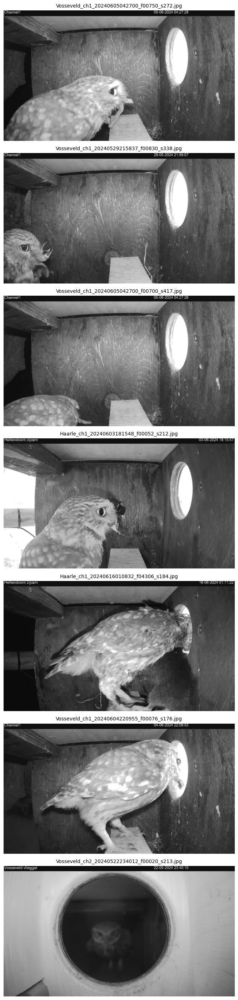

In [39]:
from PIL import Image
import matplotlib.pyplot as plt
import random

sample = false_negatives[:7]

fig, axes = plt.subplots(len(sample), 1, figsize=(12, 4 * len(sample)))

if len(sample) == 1:
    axes = [axes]

for ax, img_path in zip(axes, sample):
    img = Image.open(img_path)
    ax.imshow(img)
    ax.set_title(img_path.name, fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [40]:
from ultralytics import YOLO

model = YOLO("yolov10n.pt")

results = model.train(
    data="/kaggle/working/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    project="/kaggle/working",
    name="owl_prey_yolov10n"
)

Ultralytics 8.4.39 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov10n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=owl_prey_yolov10n, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, pati

In [41]:
from ultralytics import YOLO

model = YOLO("/kaggle/working/owl_prey_yolov10n/weights/best.pt")

model.predict(
    source="/kaggle/input/datasets/dmitrychuprin/owl-prey/owl_prey_yolo_dataset/images/val",
    conf=0.25,
    save=True
)


image 1/120 /kaggle/input/datasets/dmitrychuprin/owl-prey/owl_prey_yolo_dataset/images/val/Haarle_ch1_20240524091444_f00096_s214.jpg: 384x640 (no detections), 16.2ms
image 2/120 /kaggle/input/datasets/dmitrychuprin/owl-prey/owl_prey_yolo_dataset/images/val/Haarle_ch1_20240524091444_f00494_s211.jpg: 384x640 (no detections), 8.1ms
image 3/120 /kaggle/input/datasets/dmitrychuprin/owl-prey/owl_prey_yolo_dataset/images/val/Haarle_ch1_20240524091444_f00550_s230.jpg: 384x640 (no detections), 8.3ms
image 4/120 /kaggle/input/datasets/dmitrychuprin/owl-prey/owl_prey_yolo_dataset/images/val/Haarle_ch1_20240524091444_f00624_s227.jpg: 384x640 (no detections), 8.2ms
image 5/120 /kaggle/input/datasets/dmitrychuprin/owl-prey/owl_prey_yolo_dataset/images/val/Haarle_ch1_20240524091444_f00628_s225.jpg: 384x640 (no detections), 8.2ms
image 6/120 /kaggle/input/datasets/dmitrychuprin/owl-prey/owl_prey_yolo_dataset/images/val/Haarle_ch1_20240525123238_f00082_s226.jpg: 384x640 (no detections), 9.5ms
image 7/

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 keypoints: None
 masks: None
 names: {0: 'prey'}
 obb: None
 orig_img: array([[[42, 42, 42],
         [37, 37, 37],
         [37, 37, 37],
         ...,
         [52, 52, 52],
         [55, 55, 55],
         [49, 49, 49]],
 
        [[40, 40, 40],
         [33, 33, 33],
         [31, 31, 31],
         ...,
         [53, 53, 53],
         [55, 55, 55],
         [49, 49, 49]],
 
        [[38, 38, 38],
         [30, 30, 30],
         [29, 29, 29],
         ...,
         [53, 53, 53],
         [56, 56, 56],
         [50, 50, 50]],
 
        ...,
 
        [[54, 54, 54],
         [54, 54, 54],
         [54, 54, 54],
         ...,
         [74, 74, 74],
         [71, 71, 71],
         [69, 69, 69]],
 
        [[54, 54, 54],
         [54, 54, 54],
         [54, 54, 54],
         ...,
         [72, 72, 72],
         [69, 69, 69],
         [66, 66, 66]],
 
        [[54, 54, 54],
      

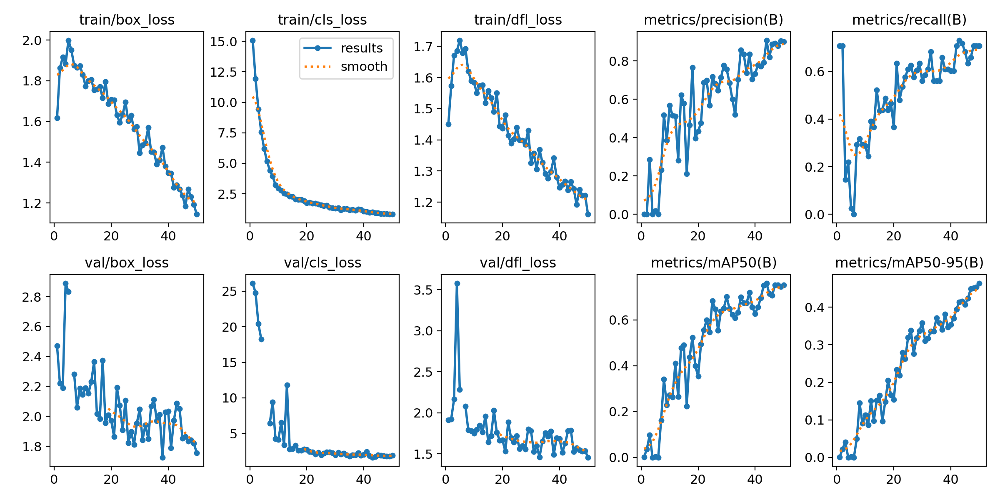

In [43]:
from IPython.display import display
from PIL import Image

display(Image.open("/kaggle/working/owl_prey_yolov10n/results.png"))

In [45]:
import pandas as pd

df = pd.read_csv("/kaggle/working/owl_prey_yolov10n/results.csv")
display(df.tail(1))

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
49,50,473.891,1.14497,0.82073,1.16131,0.89993,0.70732,0.75321,0.46364,1.75644,1.88982,1.45613,0.00006,0.00006,0.00006


In [46]:
from ultralytics import YOLO
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

dataset_dir = Path("/kaggle/input/datasets/dmitrychuprin/owl-prey/owl_prey_yolo_dataset/")
images_dir = dataset_dir / "images" / "val"
labels_dir = dataset_dir / "labels" / "val"

model = YOLO("/kaggle/working/owl_prey_yolov10n/weights/best.pt")

def has_gt(label_path):
    if not label_path.exists():
        return False
    return bool(label_path.read_text().strip())

false_negatives = []
false_positives = []

for img_path in images_dir.glob("*"):
    lbl_path = labels_dir / f"{img_path.stem}.txt"

    gt = has_gt(lbl_path)

    result = model.predict(source=str(img_path), conf=0.25, verbose=False)[0]
    pred = len(result.boxes) > 0

    if gt and not pred:
        false_negatives.append(img_path)

    if (not gt) and pred:
        false_positives.append(img_path)

print("False Negatives:", len(false_negatives))
print("False Positives:", len(false_positives))

False Negatives: 12
False Positives: 1


In [47]:
from ultralytics import YOLO

model = YOLO("rtdetr-l.pt")

results = model.train(
    data="/kaggle/working/data.yaml",
    epochs=50,
    imgsz=640,
    batch=8,
    project="/kaggle/working",
    name="owl_prey_rtdetr"
)

Ultralytics 8.4.39 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=owl_prey_rtdetr, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patienc

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       1/50      6.61G     0.6732      6.748      0.353          4        640: 100% ━━━━━━━━━━━━ 67/67 1.3it/s 52.2s0.9ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.9it/s 4.3s0.4ss
                   all        120         41      0.698      0.366      0.413      0.194

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       2/50      7.03G     0.7592     0.5653     0.4959          9        640: 0% ──────────── 0/67  0.6s

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       2/50      7.03G     0.7043     0.8244     0.4073          6        640: 100% ━━━━━━━━━━━━ 67/67 1.6it/s 42.2s0.6ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 3.4it/s 2.3s0.3s
                   all        120         41       0.68      0.363      0.399      0.157

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       3/50      7.03G      0.639     0.6268     0.2103          6        640: 0% ──────────── 0/67  0.6s

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (91 outputs left out)

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      49/50      7.25G     0.3734     0.4611     0.1986          3        640: 100% ━━━━━━━━━━━━ 67/67 1.6it/s 41.3s0.6ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 3.4it/s 2.4s0.3s
                   all        120         41      0.887      0.768      0.825       0.41

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      50/50      7.25G     0.4526     0.4958     0.2847          4        640: 0% ──────────── 0/67  0.6s

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      50/50      7.25G     0.3646     0.4506     0.1914          2        640: 100% ━━━━━━━━━━━━ 67/67 1.6it/s 41.4s0.6ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 3.4it/s 2.3s0.3s
                   all        120         41      0.867      0.798      0.826      0.431

50 epochs completed in 0.632 hours.
Optimizer stripped from /kaggle/working/owl_prey_rtdetr/weights/last.pt, 66.2MB
Optimizer stripped from /kaggle/working/owl_prey_rtdetr/weights/best.pt, 66.2MB

Validating /kaggle/working/owl_prey_rtdetr/weights/best.pt...
Ultralytics 8.4.39 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
rt-detr-l summary: 310 layers, 31,985,795 parameters, 0 gradients, 103.4 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 3.0it/s 2.7s0.3s
                   all        120         41      0.867      0.799      0.826      0.434
Speed: 0.2ms prepro

In [48]:
from ultralytics import YOLO

model = YOLO("/kaggle/working/owl_prey_rtdetr/weights/best.pt")

model.predict(
    source="/kaggle/input/datasets/dmitrychuprin/owl-prey/owl_prey_yolo_dataset/images/val",
    conf=0.25,
    save=True
)


image 1/120 /kaggle/input/datasets/dmitrychuprin/owl-prey/owl_prey_yolo_dataset/images/val/Haarle_ch1_20240524091444_f00096_s214.jpg: 640x640 (no detections), 66.6ms
image 2/120 /kaggle/input/datasets/dmitrychuprin/owl-prey/owl_prey_yolo_dataset/images/val/Haarle_ch1_20240524091444_f00494_s211.jpg: 640x640 (no detections), 65.1ms
image 3/120 /kaggle/input/datasets/dmitrychuprin/owl-prey/owl_prey_yolo_dataset/images/val/Haarle_ch1_20240524091444_f00550_s230.jpg: 640x640 (no detections), 62.5ms
image 4/120 /kaggle/input/datasets/dmitrychuprin/owl-prey/owl_prey_yolo_dataset/images/val/Haarle_ch1_20240524091444_f00624_s227.jpg: 640x640 (no detections), 58.6ms
image 5/120 /kaggle/input/datasets/dmitrychuprin/owl-prey/owl_prey_yolo_dataset/images/val/Haarle_ch1_20240524091444_f00628_s225.jpg: 640x640 (no detections), 57.0ms
image 6/120 /kaggle/input/datasets/dmitrychuprin/owl-prey/owl_prey_yolo_dataset/images/val/Haarle_ch1_20240525123238_f00082_s226.jpg: 640x640 (no detections), 58.8ms
ima

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 keypoints: None
 masks: None
 names: {0: 'prey'}
 obb: None
 orig_img: array([[[42, 42, 42],
         [37, 37, 37],
         [37, 37, 37],
         ...,
         [52, 52, 52],
         [55, 55, 55],
         [49, 49, 49]],
 
        [[40, 40, 40],
         [33, 33, 33],
         [31, 31, 31],
         ...,
         [53, 53, 53],
         [55, 55, 55],
         [49, 49, 49]],
 
        [[38, 38, 38],
         [30, 30, 30],
         [29, 29, 29],
         ...,
         [53, 53, 53],
         [56, 56, 56],
         [50, 50, 50]],
 
        ...,
 
        [[54, 54, 54],
         [54, 54, 54],
         [54, 54, 54],
         ...,
         [74, 74, 74],
         [71, 71, 71],
         [69, 69, 69]],
 
        [[54, 54, 54],
         [54, 54, 54],
         [54, 54, 54],
         ...,
         [72, 72, 72],
         [69, 69, 69],
         [66, 66, 66]],
 
        [[54, 54, 54],
      

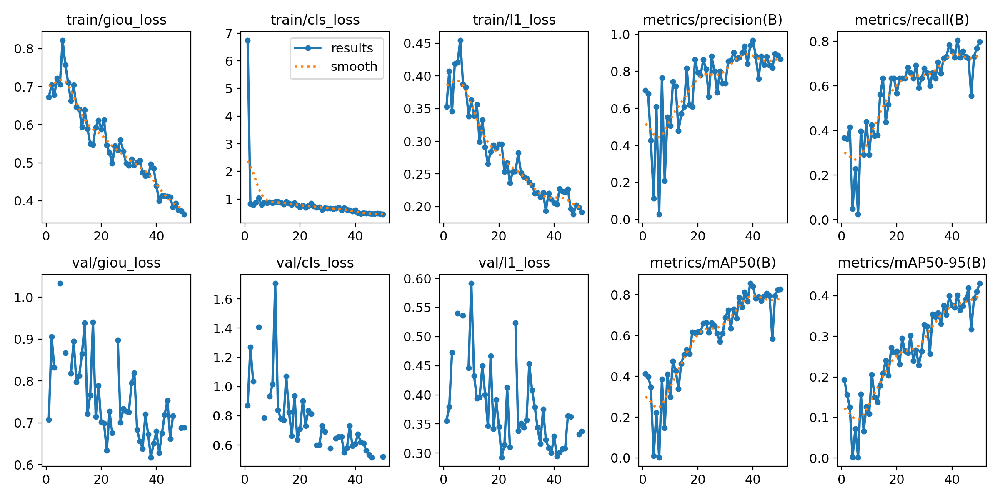

In [49]:
from IPython.display import display
from PIL import Image

display(Image.open("/kaggle/working/owl_prey_rtdetr/results.png"))

In [51]:
import pandas as pd

df = pd.read_csv("/kaggle/working/owl_prey_rtdetr/results.csv")
display(df.tail(1))

,epoch,time,train/giou_loss,train/cls_loss,train/l1_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/giou_loss,val/cls_loss,val/l1_loss,lr/pg0,lr/pg1,lr/pg2
49,50,2273.35,0.36458,0.45064,0.19144,0.86746,0.79826,0.82616,0.4307,0.68864,0.52057,0.33723,0.00006,0.00006,0.00006


In [52]:
from ultralytics import YOLO
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

dataset_dir = Path("/kaggle/input/datasets/dmitrychuprin/owl-prey/owl_prey_yolo_dataset/")
images_dir = dataset_dir / "images" / "val"
labels_dir = dataset_dir / "labels" / "val"

model = YOLO("/kaggle/working/owl_prey_rtdetr/weights/best.pt")

def has_gt(label_path):
    if not label_path.exists():
        return False
    return bool(label_path.read_text().strip())

false_negatives = []
false_positives = []

for img_path in images_dir.glob("*"):
    lbl_path = labels_dir / f"{img_path.stem}.txt"

    gt = has_gt(lbl_path)

    result = model.predict(source=str(img_path), conf=0.25, verbose=False)[0]
    pred = len(result.boxes) > 0

    if gt and not pred:
        false_negatives.append(img_path)

    if (not gt) and pred:
        false_positives.append(img_path)

print("False Negatives:", len(false_negatives))
print("False Positives:", len(false_positives))

False Negatives: 4
False Positives: 3


In [57]:
import pandas as pd

model_runs = {
    "YOLOv8n": "/kaggle/working/owl_prey_yolov8n/results.csv",
    "YOLOv10n": "/kaggle/working/owl_prey_yolov10n/results.csv",
    "RT-DETR": "/kaggle/working/owl_prey_rtdetr/results.csv",
}

rows = []

for model_name, csv_path in model_runs.items():
    df = pd.read_csv(csv_path)
    last = df.iloc[-1]

    rows.append({
        "Model": model_name,
        "Epoch": int(last["epoch"]) if "epoch" in df.columns else len(df),
        "Precision": last["metrics/precision(B)"],
        "Recall": last["metrics/recall(B)"],
        "mAP50": last["metrics/mAP50(B)"],
        "mAP50-95": last["metrics/mAP50-95(B)"],
    })

summary_df = pd.DataFrame(rows)

summary_df = summary_df.sort_values(by="mAP50", ascending=False).reset_index(drop=True)

display(summary_df)

,Model,Epoch,Precision,Recall,mAP50,mAP50-95
0,YOLOv8n,50,0.99536,0.78049,0.88104,0.54339
1,RT-DETR,50,0.86746,0.79826,0.82616,0.43070
2,YOLOv10n,50,0.89993,0.70732,0.75321,0.46364


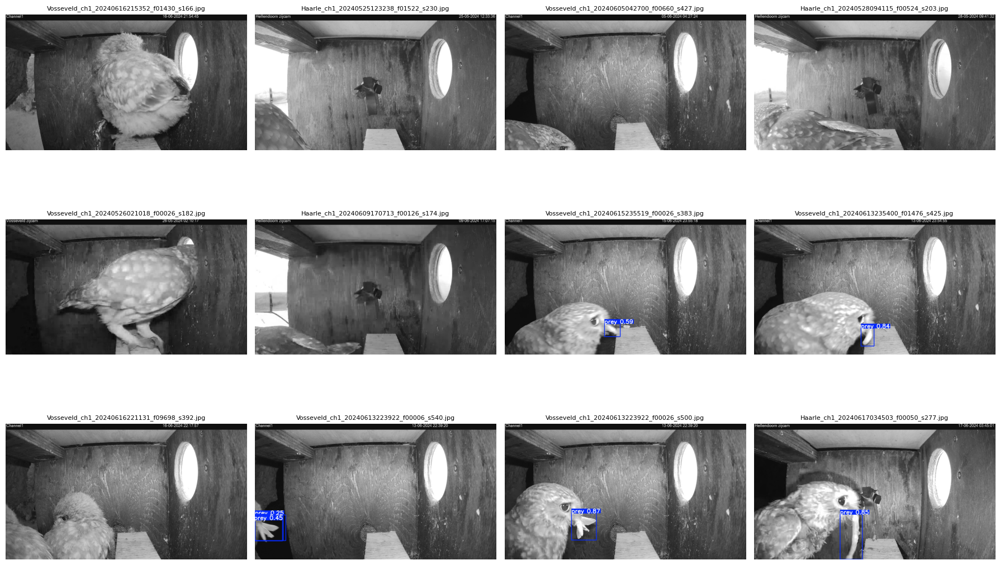

In [54]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import random

pred_dir = Path("/kaggle/working/runs/detect/predict-3")
images = list(pred_dir.glob("*"))

random.seed(42)
sample = random.sample(images, min(12, len(images)))

fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for ax, img_path in zip(axes, sample):
    img = Image.open(img_path)
    ax.imshow(img)
    ax.set_title(img_path.name, fontsize=8)
    ax.axis("off")

for i in range(len(sample), len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()

Three object detection models (YOLOv8n, YOLOv10n, and RT-DETR) were evaluated on the pilot dataset. Among them, YOLOv8n achieved the best overall performance, with the highest mAP50 (0.881) and mAP50-95 (0.543), as well as near-perfect precision (0.995). This indicates that the model provides the most accurate and reliable detections.

RT-DETR showed the highest recall (0.798), meaning it was slightly better at detecting all prey instances, but it underperformed in precision and localization quality compared to YOLOv8n. YOLOv10n demonstrated the weakest results across most metrics and did not improve upon the baseline.

Overall, YOLOv8n was selected as the optimal model for the pilot stage due to its strong balance between accuracy, robustness, and detection quality.